In [1]:
import os
import pandas as pd
import scanpy as sc
import anndata
import numpy as np

/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
old_pd = sc.read_mtx('/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/junker/matrix.mtx').T

In [3]:
gene_names = pd.read_table("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/junker/features.tsv", header=None)[1]

In [4]:
gene_names 

0            ptpn12
1             phtf2
2             phtf2
3        CU856344.2
4        CU856344.1
            ...    
31467         BIRC5
31468          EGFP
31469       mCherry
31470       dTomato
31471          rfp1
Name: 1, Length: 31472, dtype: object

In [6]:
cell_names = pd.read_table("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/junker/barcodes.tsv", header=None)[0]

In [7]:
cell_names = [i[:-2] for i in cell_names] #remove "-1" at the end

In [8]:
old_pd.obs_names = cell_names

In [9]:
old_pd.var_names = gene_names

In [11]:
meta_data = pd.read_csv("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/junker/metadata_larva_z5.csv", sep=",")

In [12]:
meta_data

,Unnamed: 0,orig.ident,nCount_RNA,nFeature_RNA,percent.mt,RNA_snn_res.0.4,seurat_clusters,celltype,cell_barcode
0,AAACCTGAGACTGTAA,z5,2713,816,1.179506,12,12,smooth_muscle,AAACCTGAGACTGTAA
1,AAACCTGAGAGCCTAG,z5,1102,478,1.361162,2,2,neurons,AAACCTGAGAGCCTAG
2,AAACCTGAGTGTTAGA,z5,1727,524,1.968732,0,0,mesodermal_origin,AAACCTGAGTGTTAGA
3,AAACCTGCAAGCGTAG,z5,11161,1833,0.842218,4,4,keratinocytes,AAACCTGCAAGCGTAG
4,AAACCTGCAGCGATCC,z5,9127,1954,4.886600,31,31,radial_glia,AAACCTGCAGCGATCC
...,...,...,...,...,...,...,...,...,...
11915,TTTGTCATCCCACTTG,z5,7208,736,0.513319,9,9,erythrocytes,TTTGTCATCCCACTTG
11916,TTTGTCATCCGCATAA,z5,12811,1597,1.061588,3,3,epidermal_cells,TTTGTCATCCGCATAA
11917,TTTGTCATCGTAGGTT,z5,1766,534,0.566251,0,0,mesodermal_origin,TTTGTCATCGTAGGTT
11918,TTTGTCATCTCGGACG,z5,8965,1393,0.780814,4,4,keratinocytes,TTTGTCATCTCGGACG


In [13]:
adata_no_nan = old_pd[old_pd.obs_names.isin(meta_data["cell_barcode"])] #only cells that passed noras quality control

In [14]:
scars_final_data = pd.read_csv("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/junker/scars_finalfilter_z5.csv", sep=",")

In [15]:
scars_final_data

,Unnamed: 0,Sequence,Barcode,Reads,CIGAR,UMI,p,Scar
0,1,GAGTTCAAGACCATCTACATGGCCAAAAAGCCCGTACGCAACTACT...,CGGCTAGTCGAATGCT,15,37M9D38M,CCTTGATTGG,4.280060e-09,858:37M9D38M
1,2,GAGTTCAAGACCATCTACATGGCCAAAAAGCCCGTGCAACTGCCCG...,CTGCTGTCAGTAGAGC,15,49M1I25M,ATCAACGGTA,4.280060e-09,859:49M1I25M
2,3,GAGTTCAAGACCATCTACATGGCCAAAAAGCCCGTGCAACTGCCCG...,CGGAGTCTCTGAGTGT,14,49M6I20M,CTATCGGGAC,4.280060e-09,860:49M6I20M
3,4,GAGTTCAAGACCATCTACATGGCCAAAAAGCCCGTGCAACTGCCCG...,CAAGTTGGTCGAATCT,37,47M3D28M,CCATCTTACA,4.280060e-09,38:47M3D28M
4,5,GAGTTCAAGACCATCTACATGGCCAAAAAGCCCGTGCAACTGCCCG...,AGAGCGACAGCAGTTT,28,47M3D28M,GCCTCTTGTC,4.280060e-09,38:47M3D28M
...,...,...,...,...,...,...,...,...
44541,44542,GAGTTCAAGACCATCTACATGGCCTACTACGTGGACACCAAGCTGG...,TGGGAAGAGTTCGCGC,59,23S52M,AAGAGCAACC,1.491672e-06,24:23S52M
44542,44543,GAGTTCAAGACCATCTACATGGCCTACTACGTGGACACCAAGCTGG...,CCCATACAGTGTTTGC,26,23S52M,ACGGAACCGG,1.491672e-06,24:23S52M
44543,44544,GAGTTCAAGACCATCTACATGGCCTACTACGTGGACACCAAGCTGG...,AGGTCATGTAACGTTC,65,23S52M,CTGGGGGAGC,1.491672e-06,24:23S52M
44544,44545,GAGTTCAAGACCATCTACATGGCCTACTACGTGGACACCAAGCTGG...,CGCTTCAGTATTCTCT,33,23S52M,GTATATCGAT,1.491672e-06,24:23S52M


In [16]:
frequency_of_barcodes = scars_final_data["Scar"].value_counts()

In [17]:
no_of_cells_with_barcode = scars_final_data["Barcode"].unique().shape[0]
no_of_cells_with_barcode

8735

In [18]:
no_of_unique_barcodes = scars_final_data["Scar"].unique().shape[0]
no_of_unique_barcodes

1764

In [19]:
from collections import Counter

def get_entries_occurring_x_or_more_times(vector, x):
    # Count the occurrences of each element in the vector
    counter = Counter(vector)

    # Filter elements that occur x or more times
    result_entries = [element for element, count in counter.items() if count >= x]

    return result_entries

In [20]:
min_no_of_barcodes = 10 

In [21]:
barcodes_more_than_x = get_entries_occurring_x_or_more_times(scars_final_data["Scar"], min_no_of_barcodes)

In [22]:
max_no_of_barcodes = 500 

In [23]:
barcodes_upper_limit = get_entries_occurring_x_or_more_times(scars_final_data["Scar"], max_no_of_barcodes) # barcodes which were generated to early -> in too many cells, we don't look at them

In [24]:
barcodes_keep = [f for f in barcodes_more_than_x if f not in barcodes_upper_limit ]

In [25]:
updated_scar_file = scars_final_data.loc[scars_final_data["Scar"].isin(barcodes_keep)]


In [26]:
updated_scar_file

,Unnamed: 0,Sequence,Barcode,Reads,CIGAR,UMI,p,Scar
18,19,GAGTTCAAGACCATCTACATGGCCAACTACTACGTGGACACCAAGC...,GTCAAGTCACAAGTAA,37,25S50M,GTTACACAGT,4.280060e-09,41:25S50M
19,20,GAGTTCAAGACCATCTACATGGCCAACTACTACGTGGACACCAAGC...,TGATTTCCATCCCATC,37,25S50M,TTGTCAGGCT,4.280060e-09,41:25S50M
20,21,GAGTTCAAGACCATCTACATGGCCAACTACTACGTGGACACCAAGC...,CCGTGGAGTTAAGGGC,27,25S50M,CTACTAAATT,4.280060e-09,41:25S50M
21,22,GAGTTCAAGACCATCTACATGGCCAACTACTACGTGGACACCAAGC...,AAGACCTCATGTTCCC,16,25S50M,AAATTGCCGT,4.280060e-09,41:25S50M
22,23,GAGTTCAAGACCATCTACATGGCCAACTACTACGTGGACACCAAGC...,CAGTCCTAGGACACCA,43,25S50M,CCCTGATTTT,4.280060e-09,41:25S50M
...,...,...,...,...,...,...,...,...
44520,44521,GAGTTCAAGACCATCTACATGGCCAGTATCTACATGGCCGTACTAC...,AGAGTGGGTACCGAGA,47,40S35M,TCGACATCCC,4.280060e-09,833:40S35M
44521,44522,GAGTTCAAGACCATCTACATGGCCAGTATCTACATGGCCGTACTAC...,CTACCCAAGCTTATCG,62,40S35M,ACTGCTACGG,4.280060e-09,833:40S35M
44522,44523,GAGTTCAAGACCATCTACATGGCCAGTATCTACATGGCCGTACTAC...,GTGGGTCTCCCGGATG,68,40S35M,GCCCAACTAT,4.280060e-09,833:40S35M
44523,44524,GAGTTCAAGACCATCTACATGGCCAGTATCTACATGGCCGTACTAC...,CGGCTAGGTCTTCAAG,57,40S35M,TTAGTTAGCA,4.280060e-09,833:40S35M


In [27]:
adata_no_nan.obs["barcode"] = None

for cell in adata_no_nan.obs_names:
    set_of_scars_for_cell = updated_scar_file.loc[updated_scar_file["Barcode"] == cell]["Scar"]
    #print(set_of_scars_for_cell.shape)
    if frequency_of_barcodes[set_of_scars_for_cell].shape[0] > 0 : 
        adata_no_nan.obs["barcode"][cell] = frequency_of_barcodes[set_of_scars_for_cell].idxmax()


/tmp/ipykernel_2332186/3222185818.py:1: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata_no_nan.obs["barcode"] = None
/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/anndata/_core/anndata.py:1840: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/anndata/_core/anndata.py:1840: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [28]:
adata_no_nan.obs["barcode"]

AAACCTGAGACTGTAA             None
AAACCTGAGAGCCTAG             None
AAACCTGAGTGTTAGA     744:42M6D33M
AAACCTGCAAGCGTAG    474:46M22D29M
AAACCTGCAGCGATCC             None
                        ...      
TTTGTCATCCCACTTG             None
TTTGTCATCCGCATAA     372:49M9I17M
TTTGTCATCGTAGGTT     492:49M8D26M
TTTGTCATCTCGGACG             None
TTTGTCATCTTAGCCC     432:49M1D26M
Name: barcode, Length: 11920, dtype: object

In [29]:
adata_no_nan = adata_no_nan[~adata_no_nan.obs["barcode"].isna()]

In [30]:
adata_no_nan.obs["cell_type"] = None

for cell in adata_no_nan.obs_names:
    adata_no_nan.obs["cell_type"][cell] = meta_data.loc[meta_data["cell_barcode"] == cell]["celltype"].values[0]

/tmp/ipykernel_2332186/1725501223.py:1: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata_no_nan.obs["cell_type"] = None
/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/anndata/_core/anndata.py:1840: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/anndata/_core/anndata.py:1840: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [31]:
adata_no_nan.obs["cell_type"]

AAACCTGAGTGTTAGA    mesodermal_origin
AAACCTGCAAGCGTAG        keratinocytes
AAACCTGGTATGGTTC      epidermal_cells
AAACCTGGTCGAGTTT      epidermal_cells
AAACCTGGTGTCTGAT          iridophores
                          ...        
TTTGTCAGTTCCCGAG     skleletal_muscle
TTTGTCAGTTTGTGTG          fibroblasts
TTTGTCATCCGCATAA      epidermal_cells
TTTGTCATCGTAGGTT    mesodermal_origin
TTTGTCATCTTAGCCC      epidermal_cells
Name: cell_type, Length: 6191, dtype: object

In [32]:
sc.pp.filter_cells(adata_no_nan, min_genes=100)
sc.pp.filter_genes(adata_no_nan, min_cells=2)

/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/anndata/_core/anndata.py:1840: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/anndata/_core/anndata.py:1840: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/anndata/_core/anndata.py:1840: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


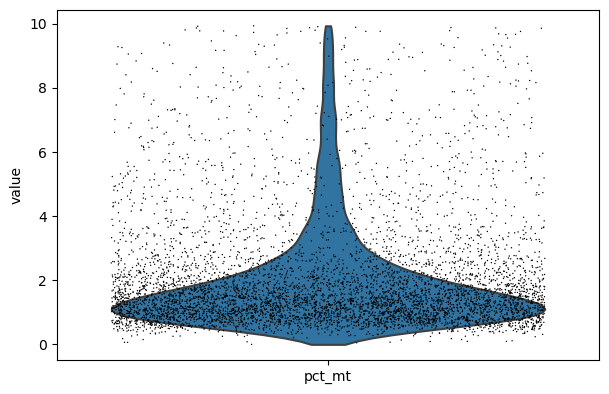

In [33]:
adata = adata_no_nan
import numpy as np
# --- 1) Compute mitochondrial percentage ---
# Identify mitochondrial genes (human or mouse)
adata.var['mt'] = adata.var_names.str.upper().str.startswith('MT-')

# Calculate percentage
adata.obs['pct_mt'] = np.sum(
    adata[:, adata.var['mt']].X, axis=1
) / np.sum(adata.X, axis=1) * 100

adata.var_names_make_unique()

sc.pl.violin(adata, 'pct_mt', jitter=0.4)

In [34]:
# preprocess
sc.pp.normalize_total(adata_no_nan, target_sum=1e4)
sc.pp.log1p(adata_no_nan)


In [44]:

adata_filtered = adata_no_nan

In [45]:
df = pd.DataFrame(adata_filtered.X.todense(), columns = adata_filtered.var_names)

In [46]:
df

,ptpn12,CU856344.1,mansc1,lrp6,dusp16,crebl2,gpr19,tbk1,eps8,ptpro,...,mt-nd4,NC_002333.16,NC_002333.15,mt-nd5,mt-nd6,mt-cyb,NC_002333.22,EGFP,dTomato,rfp1
0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,...,0.000000,0.0,0.0,1.907650,0.0,3.963383,0.0,0.000000,0.0,4.530401
1,0.0,0.0,0.0,0.0,0.0,0.632495,0.632495,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.632495,0.0,2.591682,0.0,1.016897,0.0,5.034600
2,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,...,1.536693,0.0,0.0,0.000000,0.0,3.686995,0.0,0.000000,0.0,5.620059
3,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,...,0.609335,0.0,0.0,0.000000,0.0,1.927812,0.0,1.471745,0.0,4.233756
4,0.0,0.0,0.0,0.0,0.0,1.361683,0.000000,0.0,0.0,0.0,...,0.000000,0.0,0.0,1.361683,0.0,2.741729,0.0,2.272978,0.0,4.572554
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6186,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,...,1.359098,0.0,0.0,0.000000,0.0,3.653378,0.0,0.000000,0.0,3.653378
6187,0.0,0.0,0.0,0.0,0.0,0.932305,0.000000,0.0,0.0,0.0,...,1.726522,0.0,0.0,0.000000,0.0,3.459691,0.0,0.000000,0.0,4.468892
6188,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,...,0.568579,0.0,0.0,0.568579,0.0,3.002901,0.0,0.000000,0.0,5.255791
6189,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.000000,0.0,1.870492,0.0,0.000000,0.0,5.713838


In [47]:
df["barcode"] = adata_filtered.obs["barcode"].values

In [48]:
barcode_df = {}
k = 0
for i in df["barcode"].unique():
    barcode_df[i] = k
    k +=1

In [49]:
df["barcode_cont"] = df["barcode"].map(barcode_df)

In [50]:
df.drop(columns = ["barcode"], inplace = True)

In [51]:
df

,ptpn12,CU856344.1,mansc1,lrp6,dusp16,crebl2,gpr19,tbk1,eps8,ptpro,...,NC_002333.16,NC_002333.15,mt-nd5,mt-nd6,mt-cyb,NC_002333.22,EGFP,dTomato,rfp1,barcode_cont
0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,...,0.0,0.0,1.907650,0.0,3.963383,0.0,0.000000,0.0,4.530401,0
1,0.0,0.0,0.0,0.0,0.0,0.632495,0.632495,0.0,0.0,0.0,...,0.0,0.0,0.632495,0.0,2.591682,0.0,1.016897,0.0,5.034600,1
2,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.0,3.686995,0.0,0.000000,0.0,5.620059,2
3,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.0,1.927812,0.0,1.471745,0.0,4.233756,3
4,0.0,0.0,0.0,0.0,0.0,1.361683,0.000000,0.0,0.0,0.0,...,0.0,0.0,1.361683,0.0,2.741729,0.0,2.272978,0.0,4.572554,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6186,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.0,3.653378,0.0,0.000000,0.0,3.653378,82
6187,0.0,0.0,0.0,0.0,0.0,0.932305,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.0,3.459691,0.0,0.000000,0.0,4.468892,102
6188,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.568579,0.0,3.002901,0.0,0.000000,0.0,5.255791,24
6189,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.0,1.870492,0.0,0.000000,0.0,5.713838,58


In [52]:
df.to_pickle("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/junker_z5_all_genes.pkl")

